##**MobileNetV3 Model (Image Classification)**
1. **Load the Image:** Image.open(urlopen(url)) loads the image directly from a URL using PIL.
2. **Display the Image:** plt.imshow(img) displays the input image using Matplotlib.
3. **Load the Pretrained Model:** timm.create_model('mobilenetv3_small_100.lamb_in1k', pretrained=True) loads a pretrained MobileNetV3 Small model trained on ImageNet-1K, containing 1,000 classes.
4. **Set Evaluation Mode:** model.eval() switches the model to evaluation mode, disabling training-specific behaviors such as dropout.
5. **Configure Image Transformations:** timm.data.resolve_model_data_config(model) retrieves the model's required input configuration, while timm.data.create_transform() creates transformations such as resizing, cropping, and normalization.
6. **Preprocess the Image:** transforms(img) resizes and normalizes the image into a tensor suitable for the model.
7. **Add a Batch Dimension:** .unsqueeze(0) adds a batch dimension, converting the image tensor from (C, H, W) to (1, C, H, W), where C represents channels, H represents height, and W represents width.
8. **Generate Predictions:** model(...) passes the preprocessed image through the model to generate prediction scores for all 1,000 ImageNet classes.
9. **Calculate Probabilities:** output.softmax(dim=1) converts the model's output scores into probabilities across the 1,000 classes. Multiplying by 100 converts them into percentages.
10. **Extract Top-5 Predictions:** torch.topk(..., k=5) returns the five highest probabilities and their corresponding class indices, helping identify the five most likely image categories.
* **Note: The class indices must be mapped to ImageNet class labels to display meaningful names, such as beignet, instead of numerical indices.**

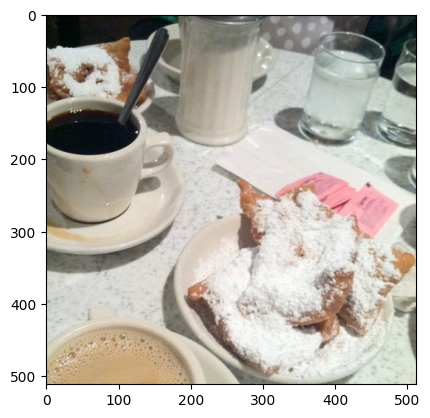

In [25]:
from urllib.request import urlopen
from PIL import Image
import timm
import torch
import matplotlib.pyplot as plt

img = Image.open(urlopen(
    'https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/beignets-task-guide.png'
))

# Ploting image
plt.imshow(img)

model = timm.create_model('mobilenetv3_small_100.lamb_in1k', pretrained=True)
model = model.eval()

# get model specific transforms (normalization, resize)
data_config = timm.data.resolve_model_data_config(model)
transforms = timm.data.create_transform(**data_config, is_training=False)

output = model(transforms(img).unsqueeze(0))  # unsqueeze single image into batch of 1

top5_probabilities, top5_class_indices = torch.topk(output.softmax(dim=1) * 100, k=5)


* **Here top k classes will be obtained whose probability is max for resembling the image (under img)**

In [26]:
print(type(top5_probabilities))
print(top5_probabilities)

<class 'torch.Tensor'>
tensor([[19.5942, 11.7788,  8.0566,  6.7019,  4.9821]],
       grad_fn=<TopkBackward0>)


In [27]:
print(type(top5_class_indices))
print(top5_class_indices)

<class 'torch.Tensor'>
tensor([[968, 969, 927, 960, 505]])


In [28]:
import urllib.request
import json

# Get ImageNet class labels
labels_url = "https://storage.googleapis.com/download.tensorflow.org/data/imagenet_class_index.json"

with urllib.request.urlopen(labels_url) as url:
    class_idx = json.loads(url.read().decode())

# Map class index to class name
idx_to_label = {int(k): v[1] for k, v in class_idx.items()}

# Print the top 5 predictions
for i, j in zip(top5_probabilities[0], top5_class_indices[0]):
    prob = round(float(i), 2)
    idx = int(j)
    class_name = idx_to_label.get(idx, "Unknown")

    print(f"Probability : {prob}% | id : {idx} | name : {class_name}")

Probability : 19.59% | id : 968 | name : cup
Probability : 11.78% | id : 969 | name : eggnog
Probability : 8.06% | id : 927 | name : trifle
Probability : 6.7% | id : 960 | name : chocolate_sauce
Probability : 4.98% | id : 505 | name : coffeepot


##**Google ViT Model (Image Classification)**
* **Trained on more than 21000 classes**
* **This a heavy pretrained model
(MobileNetV3 is a light model)**
* **Based on Vision Transformer architecture**


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Predicted class: Egyptian cat


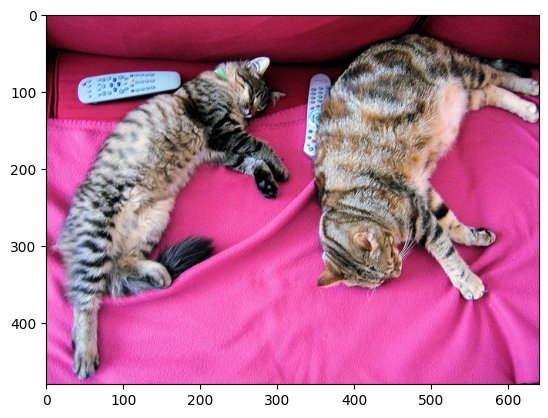

In [30]:
from transformers import ViTImageProcessor, ViTForImageClassification
from PIL import Image
import requests

url = 'http://images.cocodataset.org/val2017/000000039769.jpg'
image = Image.open(requests.get(url, stream=True).raw)

processor = ViTImageProcessor.from_pretrained('google/vit-base-patch16-224')
model = ViTForImageClassification.from_pretrained('google/vit-base-patch16-224')

inputs = processor(images=image, return_tensors="pt")
outputs = model(**inputs)
logits = outputs.logits
# model predicts one of the 1000 ImageNet classes
predicted_class_idx = logits.argmax(-1).item()
print("Predicted class:", model.config.id2label[predicted_class_idx])
plt.imshow(image)

##**DistilBert Uncased Model (Text Classification)**
* **Predicts sentiment of a sentence**

In [34]:
import torch
from transformers import DistilBertTokenizer, DistilBertForSequenceClassification

tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased-finetuned-sst-2-english")
model = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased-finetuned-sst-2-english")

inputs = tokenizer("I love badminton", return_tensors="pt")
with torch.no_grad():
    logits = model(**inputs).logits

predicted_class_id = logits.argmax().item()
model.config.id2label[predicted_class_id]


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

'POSITIVE'

**Sentiment analysis on feedback queries**

In [38]:
feedback_queries = [
    "The footwork drills helped me move much faster on court, highly recommend!",
    "I felt the coaching was very impatient and we barely got any actual play time.",
    "Can you clarify what time the Saturday intermediate session starts?",
    "The trainer explained the backhand grip perfectly; I can finally clear deep!",
    "The venue was extremely hot and poorly ventilated, making it hard to focus.",
    "Is there any membership discount for booking a block of ten lessons?",
    "The coaches are incredibly supportive and break down complex shots step-by-step.",
    "I didn't see much improvement in my game and the court fees are too expensive.",
    "We practiced basic drop shots and smashes today during the 1-hour session.",
    "The multi-shuttle drills were exhausting but outstanding for building stamina!",
    "The rackets provided by the club are quite worn out and need restocking.",
    "I absolutely loved the friendly tournament arranged at the end of the course!",
    "What is the recommended age limit for enrolling in the youth badminton program?",
    "The tactics on doubles positioning were highly practical and eye-opening.",
    "The lessons are structured well, but the group size is a bit too large for individual attention.",
    "Could we have an option to pay per session instead of paying for the whole month upfront?",
    "Our trainer gave great tips on wrist snap that instantly improved my smash power.",
    "The scheduling process is confusing and we often don't know who our coach will be.",
    "We will be using court 3 and court 4 for the serving practice today.",
    "The level of training is perfect for beginners and the atmosphere is very welcoming!"
]

# Returning only negative queries
print("Negative Feedbacks :-")
for sentence in feedback_queries:
    inputs = tokenizer(sentence, return_tensors="pt")
    with torch.no_grad():
        logits = model(**inputs).logits
    predicted_class_id = logits.argmax().item()
    sentiment = model.config.id2label[predicted_class_id]
    if str(sentiment).lower() == 'negative' :
       print(f"[{sentiment}] - {sentence}")

Negative Feedbacks :-
[NEGATIVE] - I felt the coaching was very impatient and we barely got any actual play time.
[NEGATIVE] - Can you clarify what time the Saturday intermediate session starts?
[NEGATIVE] - The venue was extremely hot and poorly ventilated, making it hard to focus.
[NEGATIVE] - Is there any membership discount for booking a block of ten lessons?
[NEGATIVE] - I didn't see much improvement in my game and the court fees are too expensive.
[NEGATIVE] - We practiced basic drop shots and smashes today during the 1-hour session.
[NEGATIVE] - The rackets provided by the club are quite worn out and need restocking.
[NEGATIVE] - What is the recommended age limit for enrolling in the youth badminton program?
[NEGATIVE] - The lessons are structured well, but the group size is a bit too large for individual attention.
[NEGATIVE] - Could we have an option to pay per session instead of paying for the whole month upfront?
[NEGATIVE] - The scheduling process is confusing and we often 

##**Roberta-base Model (Text Classification)**
* **Model trained from roberta-base on the go_emotions dataset for multi-label classification.**

In [40]:
from transformers import pipeline

classifier = pipeline(task="text-classification", model="SamLowe/roberta-base-go_emotions", top_k=None)

# Run emotion analysis on our 20 badminton feedback queries
model_outputs = classifier(feedback_queries)

# Print the top predicted emotion and its score for each feedback query
print("top predicted emotion and its score for each feedback query :-")
for sentence, output in zip(feedback_queries, model_outputs):
    # Sort the emotions by score descending and get the top one
    top_emotion = sorted(output, key=lambda x: x['score'], reverse=True)[0]
    emotion_name = top_emotion['label']
    score = round(top_emotion['score'] * 100, 2)
    print(f"[{emotion_name} - {score}%] : {sentence}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

top predicted emotion and its score for each feedback query :-
[approval - 53.79%] : The footwork drills helped me move much faster on court, highly recommend!
[annoyance - 45.24%] : I felt the coaching was very impatient and we barely got any actual play time.
[curiosity - 71.64%] : Can you clarify what time the Saturday intermediate session starts?
[approval - 59.71%] : The trainer explained the backhand grip perfectly; I can finally clear deep!
[disappointment - 54.81%] : The venue was extremely hot and poorly ventilated, making it hard to focus.
[curiosity - 62.87%] : Is there any membership discount for booking a block of ten lessons?
[approval - 41.76%] : The coaches are incredibly supportive and break down complex shots step-by-step.
[disappointment - 76.03%] : I didn't see much improvement in my game and the court fees are too expensive.
[neutral - 89.48%] : We practiced basic drop shots and smashes today during the 1-hour session.
[admiration - 37.9%] : The multi-shuttle drill

##**Google-t5/t5-small Model (Translation)**
* **Translates english sentences to French**

In [44]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Load the pretrained T5 model
model_name = "google-t5/t5-small"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

# 5 diverse sentences for translation
custom_sentences = [
    "I am learning how to play badminton with a private coach.",
    "The weather today is perfect for outdoor activities.",
    "Can you please show me the way to the nearest sports complex?",
    "Artificial intelligence is transforming the way we analyze sports data.",
    "I hope to improve my skills before the upcoming tournament."
]

# Translate and print the results
print("Translation Results (English to French):\n")

for original in custom_sentences:
    inputs = tokenizer(
        "translate English to French: " + original,
        return_tensors="pt",
        truncation=True
    )

    outputs = model.generate(**inputs, max_new_tokens=100)
    translated = tokenizer.decode(outputs[0], skip_special_tokens=True)

    print(f"Original: {original}")
    print(f"Translated: {translated}\n")

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Translation Results (English to French):

Original: I am learning how to play badminton with a private coach.
Translated: Je m'apprends à jouer de badminton avec un entraîneur privé.

Original: The weather today is perfect for outdoor activities.
Translated: Le temps d'aujourd'hui est parfait pour les activités en plein air.

Original: Can you please show me the way to the nearest sports complex?
Translated: Pouvez-vous me montrer le chemin vers le plus proche complexe sportif?

Original: Artificial intelligence is transforming the way we analyze sports data.
Translated: L'intelligence artificielle transforme la façon dont nous analysons les données sportives.

Original: I hope to improve my skills before the upcoming tournament.
Translated: J'espère améliorer mes compétences avant le prochain tournoi.



##**Qwen3 Model (Text to speech)**

In [2]:
# installing required package
!pip install -U qwen-tts

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of gradio to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of gradio to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 35.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 60.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.3/32.3 MB 46.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━

* **wavs:** A collection of generated audio waveforms, typically one waveform per input text (wavs[0]: The waveform for the first input sentence)
* **Single Inference:** This generates speech for one sentence.
* **Batch Inference:** Allows you to generate speech for multiple sentences in a single function call.

| Parameter | Explanation |
|---|---|
| `text` | The input sentence to convert into speech. |
| `language="Chinese"` | Specifies that the input text is Chinese. |
| `speaker="Vivian"` | Selects the predefined Vivian voice. |
| `instruct` | Requests a particular speaking style or emotion. Here, it requests an especially angry tone. |


In [4]:
import torch
import soundfile as sf
from qwen_tts import Qwen3TTSModel

model = Qwen3TTSModel.from_pretrained(
    "Qwen/Qwen3-TTS-12Hz-1.7B-CustomVoice",
    device_map="cuda:0",
    dtype=torch.bfloat16,
    attn_implementation="sdpa"
)

# Single inference
wavs, sr = model.generate_custom_voice(
    text="其实我真的有发现，我是一个特别善于观察别人情绪的人。",
    language="Chinese",
    speaker="Vivian",
    instruct="用特别愤怒的语气说"
)

sf.write("output_custom_voice.wav", wavs[0], sr)

# Batch inference
wavs, sr = model.generate_custom_voice(
    text=[
        "其实我真的有发现，我是一个特别善于观察别人情绪的人。",
        "She said she would be here by noon."
    ],
    language=["Chinese", "English"],
    speaker=["Vivian", "Ryan"],
    instruct=["", "Very happy."]
)

sf.write("output_custom_voice_1.wav", wavs[0], sr)
sf.write("output_custom_voice_2.wav", wavs[1], sr)

generation_config.json:   0%|          | 0.00/245 [00:00<?, ?B/s]

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

config.json: 0.00B [00:00, ?B/s]

configuration.json:   0%|          | 0.00/76.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/234 [00:00<?, ?B/s]

speech_tokenizer/model.safetensors:   0%|          | 0.00/682M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/127 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.
Setting `pad_token_id` to `eos_token_id`:2150 for open-end generation.


##**Image Classification**
* **When model is not mentioned then default model under that pipeline will be used.**
* **Like here in image-classification pipeline, google/vit-base-patch16 model is used.**

No model was supplied, defaulted to google/vit-base-patch16-224 and revision 3f49326 (https://huggingface.co/google/vit-base-patch16-224).
Using a pipeline without specifying a model name and revision in production is not recommended.
Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.
Device set to use cuda:0


[{'label': 'Egyptian cat', 'score': 0.9374414682388306}, {'label': 'tabby, tabby cat', 'score': 0.03844264894723892}, {'label': 'tiger cat', 'score': 0.01441141590476036}, {'label': 'lynx, catamount', 'score': 0.003274328541010618}, {'label': 'Siamese cat, Siamese', 'score': 0.0006795940571464598}]


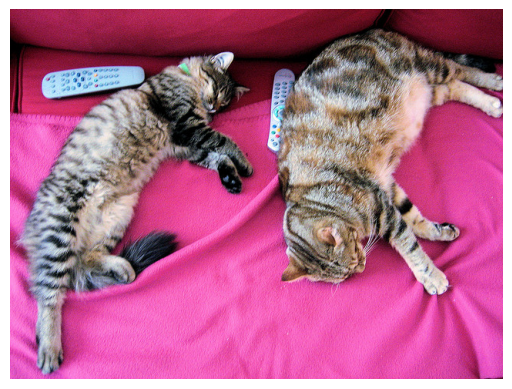

In [13]:
from io import BytesIO

image_classifier = pipeline("image-classification")

image_url = "http://images.cocodataset.org/val2017/000000039769.jpg"
response = requests.get(image_url)
image = Image.open(BytesIO(response.content))

classification_results = image_classifier(image)

print(classification_results)

plt.imshow(image)
plt.axis("off")
plt.show()